#### Autor: Leandro de Oliveira Nunes
#### Data ultima atualização: 01/11/2026
#### Estatistica e Banco de Dados (Series, leitura de CSV, DATAFRAME AVANÇADO E ESTATÍSTICA DESCRITIVA)

### Introdução às Series e Leitura de CSV

Exercício 1: Análise de Vendas  
Enunciado:
Crie um programa que analise um conjunto de dados de vendas. O programa deve ser estruturado em funções e seguir as instruções abaixo:

Função le_dados_vendas(nome_arquivo): Esta função deve ler um arquivo CSV contendo informações de vendas com as colunas: Produto, Quantidade, Preço e retornar um DataFrame.

Função calcula_receita(df): Esta função deve receber um DataFrame e calcular a receita total de cada produto (multiplicando Quantidade por Preço). A receita deve ser adicionada como uma nova coluna chamada Receita.

Função total_vendas_por_produto(df): Esta função deve agrupar os dados por produto e calcular o total de vendas (soma das quantidades) e a receita total (soma das receitas). Retorne um novo DataFrame contendo o total de vendas e a receita por produto.

Função filtra_produtos_altas_vendas(df, limite): Esta função deve filtrar o DataFrame para retornar apenas os produtos cuja receita total é superior a um valor limite passado como argumento.

Função analise_vendas(nome_arquivo): Esta função deve orquestrar as chamadas das funções anteriores, retornando o DataFrame final com os produtos que geraram mais de R$ 500,00 em receita.

In [1]:
import pandas as pd

# Função para ler o arquivo CSV de vendas e retornar um DataFrame
def le_dados_vendas(nome_arquivo): # Lê o CSV de vendas e devolve um DataFrame
    df = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega as colunas Produto, Quantidade e Preco
    return df # Devolve o DataFrame lido

df_vendas = le_dados_vendas("c:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\vendas.csv") # Chamada logo após a definição
print("--- DADOS LIDOS ---")
print(df_vendas) # Exibe os dados lidos

# Função para calcular a receita total de cada produto e adicionar como nova coluna
def calcula_receita(df): # Recebe o DataFrame e adiciona a coluna Receita
    df["Receita"] = df["Quantidade"] * df["Preco"] # Multiplica Quantidade por Preco em cada linha
    return df # Devolve o DataFrame com a nova coluna

df_vendas = calcula_receita(df_vendas) # Chamada logo após a definição para adicionar a coluna Receita
print("\n--- COM A RECEITA ---")
print(df_vendas) # Exibe os dados com a nova coluna Receita

# Função para agrupar por produto e calcular total de vendas e receita
def total_vendas_por_produto(df): # Agrupa por produto e soma quantidade e receita
    resumo = df.groupby("Produto").agg( # Agrupa as linhas pelo nome do produto
        Total_Vendas=("Quantidade", "sum"), # Soma das quantidades de cada produto
        Receita_Total=("Receita", "sum") # Soma das receitas de cada produto
    )
    return resumo # Devolve o resumo por produto

# Chamada logo após a definição
resumo_produtos = total_vendas_por_produto(df_vendas) # Chamada logo após a definição
print("\n--- TOTAL POR PRODUTO ---")
print(resumo_produtos) # Exibe o resumo por produto com total de vendas e receita

# Função para filtrar produtos com receita acima de um limite
def filtra_produtos_altas_vendas(df, limite): # Mantém só os produtos com receita acima do limite
    filtro = df["Receita_Total"] > limite # Máscara: True onde a receita é maior que o limite
    return df[filtro] # Devolve só as linhas que atendem à condição

# Chamada logo após a definição
produtos_altos = filtra_produtos_altas_vendas(resumo_produtos, 500) # Chamada logo após a definição
print("\n--- PRODUTOS ACIMA DO LIMITE ---")
print(produtos_altos) # Exibe os produtos com receita acima do limite de R$ 500,00

# Função para orquestrar todas as funções anteriores
def analise_vendas(nome_arquivo): # Orquestra todas as funções anteriores
    df = le_dados_vendas(nome_arquivo) # Lê o arquivo
    df = calcula_receita(df) # Adiciona a coluna Receita
    resumo = total_vendas_por_produto(df) # Agrupa por produto
    resultado = filtra_produtos_altas_vendas(resumo, 500) # Mantém produtos com mais de R$ 500,00
    return resultado # Devolve o DataFrame final

# Chamada da função analise_vendas para obter o resultado final
resultado_final = analise_vendas("../Data/vendas.csv") # Chamada da função analise_vendas para obter o resultado final
print("\n--- RESULTADO FINAL (receita acima de R$ 500,00) ---")
print(resultado_final) # Exibe o resultado final com produtos que geraram mais de R$ 500,00 em receita

--- DADOS LIDOS ---
    Produto  Quantidade  Preco
0  Notebook          10   75.0
1  Notebook           4   80.0
2     Mouse          20   25.0
3     Mouse          15   30.0
4   Teclado          12   45.0
5   Teclado           8   50.0
6   Monitor           5  400.0
7   Monitor           3  420.0

--- COM A RECEITA ---
    Produto  Quantidade  Preco  Receita
0  Notebook          10   75.0    750.0
1  Notebook           4   80.0    320.0
2     Mouse          20   25.0    500.0
3     Mouse          15   30.0    450.0
4   Teclado          12   45.0    540.0
5   Teclado           8   50.0    400.0
6   Monitor           5  400.0   2000.0
7   Monitor           3  420.0   1260.0

--- TOTAL POR PRODUTO ---
          Total_Vendas  Receita_Total
Produto                              
Monitor              8         3260.0
Mouse               35          950.0
Notebook            14         1070.0
Teclado             20          940.0

--- PRODUTOS ACIMA DO LIMITE ---
          Total_Vendas  Recei

Exercício 2: Análise de Notas de Alunos  
Desenvolva um programa que analise as notas de alunos. O programa deve ser estruturado em funções e seguir as instruções abaixo:

Função le_dados_alunos(nome_arquivo): Esta função deve ler um arquivo CSV contendo informações de alunos com as colunas: Nome, Nota1, Nota2, Nota3 e retornar um DataFrame.

Função calcula_media(df): Esta função deve calcular a média das notas de cada aluno e adicionar uma nova coluna chamada Media ao DataFrame.

Função verifica_aprovacao(df): Esta função deve adicionar uma nova coluna chamada Aprovado, que deve conter True se a média do aluno for maior ou igual a 7 e False caso contrário.

Função separa_alunos_aprovados_reprovados(df): Esta função deve separar os alunos em dois DataFrames: um para aprovados e outro para reprovados, com base na coluna Aprovado.

Função analise_notas(nome_arquivo): Esta função deve orquestrar as chamadas das funções anteriores e retornar os DataFrames de alunos aprovados e reprovados.

In [2]:
import pandas as pd

# Função para ler o arquivo CSV de notas e retornar um DataFrame
def le_dados_alunos(nome_arquivo): # Lê o CSV de notas e devolve um DataFrame
    df = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega as colunas Nome, Nota1, Nota2 e Nota3
    return df # Devolve o DataFrame lido que contém as notas dos alunos

# Chamada logo após a definição
df_alunos = le_dados_alunos("c:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\notas.csv") # Chamada logo após a definição
print("--- DADOS LIDOS ---")
print(df_alunos) # Exibe os dados lidos dos alunos

# Função para calcular a média das notas e adicionar como nova coluna
def calcula_media(df): # Recebe o DataFrame e adiciona a coluna Media
    df["Media"] = (df["Nota1"] + df["Nota2"] + df["Nota3"]) / 3 # Soma as três notas de cada aluno e divide por 3
    return df # Devolve o DataFrame com a nova coluna media

# Chamada logo após a definição
df_alunos = calcula_media(df_alunos) # Chamada logo após a definição para adicionar a coluna Media
print("\n--- COM A MÉDIA ---")
print(df_alunos) # Exibe os dados com a nova coluna Media

# Função para verificar aprovação dos alunos e adicionar como nova coluna
def verifica_aprovacao(df): # Recebe o DataFrame e adiciona a coluna Aprovado
    df["Aprovado"] = df["Media"] >= 7 # True se a média for maior ou igual a 7, senão False para cada aluno
    return df # Devolve o DataFrame com a nova coluna que indica se o aluno foi aprovado ou reprovado

# Chamada logo após a definição
df_alunos = verifica_aprovacao(df_alunos) # Chamada logo após a definição para adicionar a coluna Aprovado
print("\n--- COM A SITUAÇÃO ---")
print(df_alunos) # Exibe os dados com a nova coluna Aprovado, indicando se o aluno foi aprovado ou reprovado

# Função para separar alunos aprovados e reprovados em dois DataFrames distintos
def separa_alunos_aprovados_reprovados(df): # Separa o DataFrame em dois, pela coluna Aprovado para True e False
    aprovados = df[df["Aprovado"] == True] # Máscara: só as linhas em que Aprovado é True para alunos aprovados
    reprovados = df[df["Aprovado"] == False] # Máscara: só as linhas em que Aprovado é False para alunos reprovados
    return aprovados, reprovados # Devolve os dois DataFrames para alunos aprovados e reprovados

aprovados, reprovados = separa_alunos_aprovados_reprovados(df_alunos) # Chamada logo após a definição (desmonta os dois retornos)
print("\n--- APROVADOS ---")
print(aprovados) # Exibe os alunos aprovados
print("\n--- REPROVADOS ---")
print(reprovados) # Exibe os alunos reprovados

def analise_notas(nome_arquivo): # Orquestra todas as funções anteriores
    df = le_dados_alunos(nome_arquivo) # Lê o arquivo de notas
    df = calcula_media(df) # Adiciona a coluna Media de cada aluno
    df = verifica_aprovacao(df) # Adiciona a coluna Aprovado de cada aluno
    aprovados, reprovados = separa_alunos_aprovados_reprovados(df) # Separa os alunos de acordo com a coluna Aprovado em dois DataFrames distintos
    return aprovados, reprovados # Devolve os dois DataFrames para alunos aprovados e reprovados

aprovados_final, reprovados_final = analise_notas("c:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\notas.csv") # Chamada logo após a definição
print("\n--- RESULTADO FINAL ---")
print(aprovados_final)
print(reprovados_final)


--- DADOS LIDOS ---
      Nome  Nota1  Nota2  Nota3
0      Ana    8.5    9.0    7.5
1    Bruno    5.0    6.0    5.5
2    Carla    7.0    8.0    7.5
3    Diego    6.0    5.5    6.0
4    Elisa    9.0    8.5    9.5
5   Felipe    4.5    5.0    6.0
6  Giovana    7.5    7.0    8.0
7     Hugo    6.5    7.0    6.0

--- COM A MÉDIA ---
      Nome  Nota1  Nota2  Nota3     Media
0      Ana    8.5    9.0    7.5  8.333333
1    Bruno    5.0    6.0    5.5  5.500000
2    Carla    7.0    8.0    7.5  7.500000
3    Diego    6.0    5.5    6.0  5.833333
4    Elisa    9.0    8.5    9.5  9.000000
5   Felipe    4.5    5.0    6.0  5.166667
6  Giovana    7.5    7.0    8.0  7.500000
7     Hugo    6.5    7.0    6.0  6.500000

--- COM A SITUAÇÃO ---
      Nome  Nota1  Nota2  Nota3     Media  Aprovado
0      Ana    8.5    9.0    7.5  8.333333      True
1    Bruno    5.0    6.0    5.5  5.500000     False
2    Carla    7.0    8.0    7.5  7.500000      True
3    Diego    6.0    5.5    6.0  5.833333     False
4    Elis

Exercício 3: Análise de Dados de Funcionários  
Enunciado:
Crie um programa que analise os dados de funcionários de uma empresa. O programa deve ser estruturado em funções e seguir as instruções abaixo:

Função le_dados_funcionarios(nome_arquivo): Esta função deve ler um arquivo CSV com as colunas: Nome, Departamento, Salário e retornar um DataFrame.

Função calcula_salario_medio(df): Esta função deve agrupar os dados por departamento e calcular o salário médio de cada um, retornando um novo DataFrame com o nome do departamento e o salário médio.

Função filtra_departamentos_alto_salario(df, limite): Esta função deve filtrar o DataFrame para retornar apenas os departamentos cuja média salarial é superior a um valor limite passado como argumento.

Função analise_funcionarios(nome_arquivo): Esta função deve orquestrar as chamadas das funções anteriores e retornar o DataFrame final com os departamentos que têm um salário médio acima de R$ 5000,00.

In [3]:
import pandas as pd

# Função para ler o arquivo CSV de funcionários e retornar um DataFrame
def le_dados_funcionarios(nome_arquivo): # Lê o CSV de funcionários e devolve um DataFrame
    df = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega as colunas Nome, Departamento e Salário
    return df # Devolve o DataFrame lido

# Chamada logo após a definição
df_funcionarios = le_dados_funcionarios("C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\funcionarios.csv") # Chamada logo após a definição
print("--- DADOS LIDOS ---")
print(df_funcionarios) # Exibe os dados lidos dos funcionários

# Função para calcular a média salarial por departamento e retornar um DataFrame com os resultados
def calcula_salario_medio(df): # Agrupa por departamento e calcula a média salarial de cada um
    medias = df.groupby("Departamento").agg( # Agrupa as linhas pelo nome do departamento
        Salario_Medio=("Salário", "mean") # Média do salário dentro de cada departamento
    )
    return medias # Devolve o DataFrame com um salário médio por departamento

# Chamada logo após a definição
medias_departamentos = calcula_salario_medio(df_funcionarios) # Chamada logo após a definição
print("\n--- SALÁRIO MÉDIO POR DEPARTAMENTO ---")
print(medias_departamentos) # Exibe o DataFrame com o salário médio por departamento

# Função para filtrar departamentos com média salarial acima de um limite
def filtra_departamentos_alto_salario(df, limite): # Mantém só os departamentos com média acima do limite
    filtro = df["Salario_Medio"] > limite # Máscara: True onde a média é maior que o limite
    return df[filtro] # Devolve só as linhas que atendem à condição 

# Chamada logo após a definição
departamentos_altos = filtra_departamentos_alto_salario(medias_departamentos, 5000) # Chamada logo após a definição de departamentos com salário médio acima de R$ 5.000,00
print("\n--- DEPARTAMENTOS ACIMA DE R$ 5.000,00 ---")
print(departamentos_altos) # Exibe os departamentos com salário médio acima do limite de R$ 5.000,00

def analise_funcionarios(nome_arquivo): # Orquestra todas as funções anteriores
    df = le_dados_funcionarios(nome_arquivo) # Lê o arquivo
    medias = calcula_salario_medio(df) # Calcula a média por departamento
    resultado = filtra_departamentos_alto_salario(medias, 5000) # Mantém departamentos com média acima de R$ 5.000,00
    return resultado # Devolve o DataFrame final

resultado_final = analise_funcionarios("C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\funcionarios.csv") # Chamada logo após a definição 
print("\n--- RESULTADO FINAL (salário médio acima de R$ 5.000,00) ---")
print(resultado_final)

--- DADOS LIDOS ---
       Nome      Departamento  Salário
0   Mariana        Tecnologia   7500.0
1     Paulo        Tecnologia   8200.0
2    Rafael        Tecnologia   6800.0
3    Bianca  Recursos Humanos   4200.0
4     Clara  Recursos Humanos   4600.0
5      João  Recursos Humanos   4400.0
6     Lucas        Financeiro   6100.0
7  Fernanda        Financeiro   5900.0
8     Pedro        Financeiro   6400.0

--- SALÁRIO MÉDIO POR DEPARTAMENTO ---
                  Salario_Medio
Departamento                   
Financeiro          6133.333333
Recursos Humanos    4400.000000
Tecnologia          7500.000000

--- DEPARTAMENTOS ACIMA DE R$ 5.000,00 ---
              Salario_Medio
Departamento               
Financeiro      6133.333333
Tecnologia      7500.000000

--- RESULTADO FINAL (salário médio acima de R$ 5.000,00) ---
              Salario_Medio
Departamento               
Financeiro      6133.333333
Tecnologia      7500.000000


O programa tem três funções auxiliares, e a função main() chama as três: uma para ler o arquivo, outra para calcular as receitas e uma terceira para resumir e filtrar os resultados.

1. Arquivo de exemplo: vendas.csv
Crie esse arquivo na mesma pasta do programa:

Produto,Quantidade,Preço  
Notebook,10,75.00  
Notebook,4,80.00  
Mouse,20,25.00  
Mouse,15,30.00  
Teclado,12,45.00  
Teclado,8,50.00  
Monitor,5,400.00  
Monitor,3,420.00  


In [ ]:
import pandas as pd

def le_dados_vendas(nome_arquivo): # Lê o CSV de vendas e devolve um DataFrame
    df_vendas = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega as colunas Nome, Departamento e Salário
    return df_vendas # Devolve o DataFrame lido

# Função para ler o arquivo CSV de vendas e retornar um DataFrame
def le_dados_vendas(): # Lê o CSV de vendas e devolve um DataFrame
    df_vendas = pd.read_csv("C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\Data\\vendas.xlsx") # Carrega as colunas Produto, Quantidade e Preço
    return df_vendas # Devolve o DataFrame lido

def calcula_receita(df): # Recebe o DataFrame e adiciona a coluna Receita
    df["Receita"] = df["Quantidade"] * df["Preco"] # Multiplica Quantidade por Preço em cada linha
    return df # Devolve o DataFrame com a nova coluna

def resume_e_filtra_vendas(df, limite): # Resume por produto e mantém os que têm receita acima do limite
    resumo = df.groupby("Produto").agg( # Agrupa as linhas pelo nome do produto
        Total_Vendas=("Quantidade", "sum"), # Soma das quantidades de cada produto
        Receita_Total=("Receita", "sum") # Soma das receitas de cada produto
    )
    filtro = resumo["Receita_Total"] > limite # Máscara: True onde a receita é maior que o limite
    return resumo[filtro] # Devolve só os produtos que atendem à condição

def main(): # Função principal: chama as três funções na ordem
    df_vendas = le_dados_vendas() # Lê o arquivo "c:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\Codigos\\vendas.csv"
    print("--- DADOS LIDOS ---")
    print(df_vendas)

    df_vendas = calcula_receita(df_vendas) # Adiciona a coluna Receita
    print("\n--- COM A RECEITA ---")
    print(df_vendas)

    resultado = resume_e_filtra_vendas(df_vendas, 500) # Resume por produto e mantém receita acima de R$ 500,00
    print("\n--- RESULTADO FINAL (receita acima de R$ 500,00) ---")
    print(resultado)

if __name__ == "__main__": # Executa main() somente quando o arquivo é rodado diretamente
    main() # Chamada da função principal


--- DADOS LIDOS ---
    Produto  Quantidade  Preco
0  Notebook          10   75.0
1  Notebook           4   80.0
2     Mouse          20   25.0
3     Mouse          15   30.0
4   Teclado          12   45.0
5   Teclado           8   50.0
6   Monitor           5  400.0
7   Monitor           3  420.0

--- COM A RECEITA ---
    Produto  Quantidade  Preco  Receita
0  Notebook          10   75.0    750.0
1  Notebook           4   80.0    320.0
2     Mouse          20   25.0    500.0
3     Mouse          15   30.0    450.0
4   Teclado          12   45.0    540.0
5   Teclado           8   50.0    400.0
6   Monitor           5  400.0   2000.0
7   Monitor           3  420.0   1260.0

--- RESULTADO FINAL (receita acima de R$ 500,00) ---
          Total_Vendas  Receita_Total
Produto                              
Monitor              8         3260.0
Mouse               35          950.0
Notebook            14         1070.0
Teclado             20          940.0


### DATAFRAME AVANÇADO E ESTATÍSTICA DESCRITIVA

### Atividade: Aplicação Profissional
Um gerente pergunta:  
"Quais clientes estão entre os 25% que mais compram?"  
Para responder precisamos conhecer:  
- Quartis  
- Percentis  
- Distribuição dos dados  
  
Use o arquivo .csv gerado na aula: vendas_data_organized_1000.csv

In [ ]:
import pandas as pd
import numpy as np

def le_dados_vendas(nome_arquivo): # Lê o CSV de vendas e devolve um DataFrame
    df_vendas = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega as colunas Nome, Departamento e Salário
    return df_vendas # Devolve o DataFrame lido

# Função para ler o arquivo CSV de vendas e retornar um DataFrame
def le_dados_vendas():  # Lê o CSV de vendas e devolve um DataFrame
    df_vendas = pd.read_csv("C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\vendas_data_organized_1000.csv")  # Carrega os dados de vendas
    return df_vendas  # Devolve o DataFrame lido

# Carregar o arquivo CSV
df_vendas = le_dados_vendas()

# Calcular os quartis
quartis = df_vendas["Valor_Total"].quantile([0.25, 0.5, 0.75])

# Calcular os percentis de 10 em 10
percentis = df_vendas["Valor_Total"].quantile(np.arange(0, 1.1, 0.1))

# Analisar a distribuição dos dados
distribuicao = df_vendas["Valor_Total"].describe()

# Exibir os resultados
print("Quartis:")
print(quartis)

print("\nPercentis:")
print(percentis)

print("\nDistribuição dos dados:")
print(distribuicao)

# Identificar as transações entre os 25% de maiores valores
limite = quartis.loc[0.75]
transacoes_top_25 = df_vendas[df_vendas["Valor_Total"] >= limite]

print("\nTransações entre os 25% de maiores valores:") # Exibir as transações com valores acima do limite do terceiro quartil (Q3), que representa os 25% de maiores valores.
print(transacoes_top_25)


Quartis:
0.25     2973.4200
0.50     6727.5850
0.75    13008.5125
Name: Valor_Total, dtype: float64

Percentis:
0.0       56.870
0.1     1386.652
0.2     2495.432
0.3     3588.432
0.4     5204.004
0.5     6727.585
0.6     8869.056
0.7    11429.634
0.8    14626.730
0.9    19894.869
1.0    31029.840
Name: Valor_Total, dtype: float64

Distribuição dos dados:
count     1000.000000
mean      8791.731850
std       7123.727855
min         56.870000
25%       2973.420000
50%       6727.585000
75%      13008.512500
max      31029.840000
Name: Valor_Total, dtype: float64

Transações entre os 25% de maiores valores:
    ID_Transacao           Data_Venda          Cidade         Categoria  \
3      TXN-10003  2024-01-01 12:00:00         Niterói  Eletrodomésticos   
9      TXN-10009  2024-01-02 12:00:00      Petrópolis       Eletrônicos   
11     TXN-10011  2024-01-02 20:00:00           Macaé       Eletrônicos   
12     TXN-10012  2024-01-03 00:00:00   Volta Redonda            Móveis   
19     TXN-1

Discussão

Qual o valor que divide os 25% menores faturamentos?  
Qual o valor que representa a mediana?  
Qual o valor dos 25% maiores faturamentos?  

In [7]:
# Exibir os resultados dos quartis
print("Q1 - 25%:", quartis.loc[0.25])
print("Mediana - 50%:", quartis.loc[0.5])
print("Q3 - 75%:", quartis.loc[0.75])

Q1 - 25%: 2973.42
Mediana - 50%: 6727.584999999999
Q3 - 75%: 13008.5125


### Atividade Prática

Cenário:

O Supervisor Sênior solicitou um relatório estatístico.

Você deverá:  

Parte 1 – Quartis da coluna Valor_Total

In [ ]:
import pandas as pd

def le_dados_vendas(nome_arquivo): # Lê o CSV de vendas e devolve um DataFrame
    df = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega a base de vendas
    return df # Devolve o DataFrame lido

df_vendas = le_dados_vendas("C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\vendas_data_organized_1000.csv") # Chamada logo após a definição
print("--- DADOS LIDOS ---")
print(f"Total de registros: {len(df_vendas)} linhas.")

def calcula_quartis(df): # Calcula Q1, Q2 e Q3 da coluna Valor_Total
    quartis = df["Valor_Total"].quantile([0.25, 0.5, 0.75]) # Calcula Q1, mediana e Q3 (25%, 50% e 75%)
    return quartis # Devolve a Series com os três quartis

quartis_valor = calcula_quartis(df_vendas) # Chamada logo após a definição
print("\n--- QUARTIS DE VALOR_TOTAL ---")
print(f"Q1 (25%): R$ {quartis_valor.loc[0.25]:,.2f}") # Primeiro quartil formatado em reais
print(f"Q2 (50%, mediana): R$ {quartis_valor.loc[0.5]:,.2f}") # Segundo quartil, igual à mediana
print(f"Q3 (75%): R$ {quartis_valor.loc[0.75]:,.2f}") # Terceiro quartil formatado em reais

--- DADOS LIDOS ---
Total de registros: 1000 linhas.

--- QUARTIS DE VALOR_TOTAL ---
Q1 (25%): R$ 2,973.42
Q2 (50%, mediana): R$ 6,727.58
Q3 (75%): R$ 13,008.51


Parte 2 – Filtrar somente Rio de Janeiro

In [ ]:
import pandas as pd

def le_dados_vendas(nome_arquivo): # Lê o CSV de vendas e devolve um DataFrame
    df = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega a base de vendas
    return df # Devolve o DataFrame lido

df_vendas = le_dados_vendas("C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\vendas_data_organized_1000.csv") # Chamada logo após a definição

def filtra_cidade(df, cidade): # Recebe o DataFrame e o nome da cidade e devolve só as vendas dessa cidade
    filtro = df["Cidade"] == cidade # Máscara booleana: True nas linhas da cidade informada que será usada para filtrar o DataFrame
    return df[filtro] # Devolve o DataFrame filtrado 

df_rio = filtra_cidade(df_vendas, "Rio de Janeiro") # Chamada logo após a definição com a cidade "Rio de Janeiro"
print("--- VENDAS DO RIO DE JANEIRO ---")
print(f"Total de registros: {len(df_rio)} linhas.") # len() conta as linhas filtradas contendo a cidade "Rio de Janeiro"
print(df_rio.head()) # Mostra as primeiras 5 linhas do filtro, pois o método head() retorna as primeiras linhas de um DataFrame, por padrão 5, mas pode-se passar um número como argumento para retornar mais ou menos linhas.

--- VENDAS DO RIO DE JANEIRO ---
Total de registros: 421 linhas.
   ID_Transacao           Data_Venda          Cidade         Categoria  \
0     TXN-10000  2024-01-01 00:00:00  Rio de Janeiro       Informática   
4     TXN-10004  2024-01-01 16:00:00  Rio de Janeiro  Eletrodomésticos   
5     TXN-10005  2024-01-01 20:00:00  Rio de Janeiro       Informática   
6     TXN-10006  2024-01-02 00:00:00  Rio de Janeiro  Eletrodomésticos   
10    TXN-10010  2024-01-02 16:00:00  Rio de Janeiro       Informática   

    Quantidade  Preco_Unitario  Valor_Total  
0            2           90.39       180.78  
4            5         2041.34     10206.70  
5            2          200.90       401.80  
6            5          474.36      2371.80  
10           2         2300.41      4600.82  


Parte 3  
Calcular: Faturamento Total, Ticket Médio, Maior Venda, Menor Venda

In [3]:
import pandas as pd

def le_dados_vendas(nome_arquivo): # Lê o CSV de vendas e devolve um DataFrame
    df = pd.read_csv(nome_arquivo, encoding="utf-8") # Carrega a base de vendas
    return df # Devolve o DataFrame lido

df_vendas = le_dados_vendas("C:\\Users\\USER_ADM\\Desktop\\Curso_Analista_Dados\\Python\\UC2\\Data\\vendas_data_organized_1000.csv") # Chamada logo após a definição
# C:\\Users\\leandro.onunes\\Documents\\Python\\UC2\\DATA\\vendas_data_organized_1000.csv

# Parte 1: Calcular o Faturamento Total
faturamento_total = df_vendas["Valor_Total"].sum() # Soma todos os valores
print(f"Faturamento Total: R$ {faturamento_total:.2f}")

# Parte 2: Calcular o Ticket Médio
ticket_medio = df_vendas["Valor_Total"].mean() # Calcula a média dos valores
print(f"Ticket Médio: R$ {ticket_medio:.2f}")

# Parte 3: Calcular a Maior Venda
maior_venda = df_vendas["Valor_Total"].max() # Encontra o valor máximo
print(f"Maior Venda: R$ {maior_venda:.2f}")

# Parte 4: Calcular a Menor Venda
menor_venda = df_vendas["Valor_Total"].min() # Encontra o valor mínimo
print(f"Menor Venda: R$ {menor_venda:.2f}")

# Plus: indicadores estatísticos de todas as cidades
print("\n--- INDICADORES ESTATÍSTICOS (TODAS AS CIDADES) ---")
print(df_vendas["Valor_Total"].describe()) # Contagem, média, desvio, mínimo, quartis e máximo de uma vez
print(f"\nFaturamento total: R$ {df_vendas['Valor_Total'].sum():,.2f}") # Soma de Valor_Total de todas as cidades

Faturamento Total: R$ 8791731.85
Ticket Médio: R$ 8791.73
Maior Venda: R$ 31029.84
Menor Venda: R$ 56.87

--- INDICADORES ESTATÍSTICOS (TODAS AS CIDADES) ---
count     1000.000000
mean      8791.731850
std       7123.727855
min         56.870000
25%       2973.420000
50%       6727.585000
75%      13008.512500
max      31029.840000
Name: Valor_Total, dtype: float64

Faturamento total: R$ 8,791,731.85


Parte 4 – Gráfico de Barras

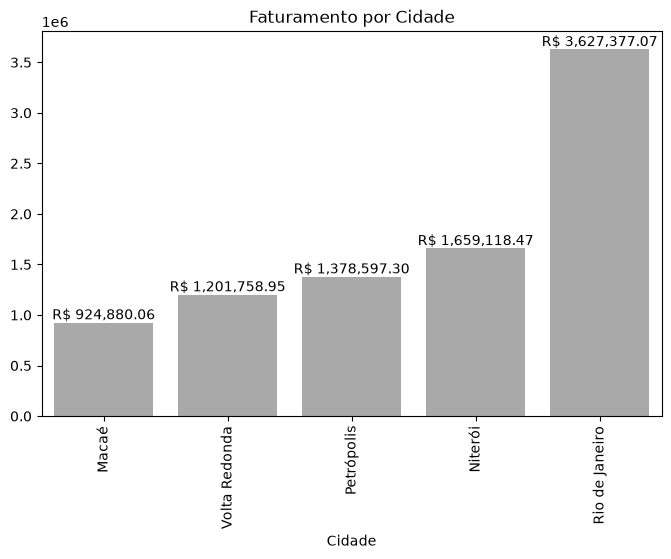

In [11]:
import matplotlib.pyplot as plt

vendas_cidade = (df_vendas.groupby("Cidade")["Valor_Total"].sum().sort_values()) # Agrupa os dados por cidade, soma o Valor_Total de cada cidade e ordena os resultados.
vendas_cidade.plot(kind="bar",figsize=(8,5), title="Faturamento por Cidade") # Cria um gráfico de barras com o título "Faturamento por Cidade" com um tamanho de 8 de largura x 5 de altura para aparecer melhor o eixo horizontal

# Adiciona o valor de cada barra no gráfico, formatado em reais
for i, (cidade, valor) in enumerate(vendas_cidade.items()): # Itera sobre cada cidade e seu valor total de vendas, enumerando para obter o índice da barra
    plt.text(i, valor, f'R$ {valor:,.2f}', ha='center', va='bottom') # Adiciona o valor de cada barra no gráfico

# Muda a cor das barras de cada cidade para cinza escuro
for i in range(len(vendas_cidade)): # Itera sobre o índice de cada barra no gráfico
    plt.bar(i, vendas_cidade.iloc[i], color='darkgray') # Muda a cor da barra para cinza escuro

Parte 5 – Questões Interpretativas
1. Qual cidade possui maior faturamento?

Justificativa:

Rio de Janeiro lidera com R$ 3.627.377,07, cerca de 41% do faturamento total (R$ 8.791.731,85).

2. A mediana está próxima da média?

Justificativa:


Não. A média é R$ 8.791,73 e a mediana é R$ 6.727,59, uma diferença de R$ 2.064,14 (cerca de 23,5% abaixo da média).   
Isso se justifica porque tem poucas vendas, mas com valores o que eleva. O que a mediana representa melhor a venda e não a média.

3. Os dados parecem equilibrados?

Justificativa:

Não. O valor de Q1 é R$2.973,42, a mediana é R$6.727,59 e o Q3 é R$13.008,51. As distância entre os quartis são de mais de R$3.000 no D1 e mais de R$6.000 no Q3 e assim é possível entender que as vendas acima da mediana são mais espalhadas. O menor valor é min = R$56,87, o maior é max = R$31.029,84 e o desvio padrão de std = R$ 7.123,73, ficando próximo da média que foi mean = R$ 8.791,73.

4. Os 25% maiores faturamentos começam em qual valor?

Justificativa:

Começam em R$ 13.008,51, que é o terceiro quartil (Q3) da base completa.  
Justificativa: o Q3 separa a base em 75% abaixo e 25% acima desse valor. Como a base tem 1.000 vendas, cerca de 250 delas estão em R$ 13.008,51 ou acima.